MobileNetV2 is a lightweight and efficient convolutional neural network (CNN) designed for mobile and embedded vision applications. It is optimized for speed and low computational cost while maintaining high accuracy.


In [2]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

In [3]:
# === 1. Setup ===
dataset_path = "../../../wheat_256px-dataset"
img_size = (224, 224)  # MobileNet's preferred input size
batch_size = 32
num_classes = 5
seed = 42

# === 2. Load and split dataset ===
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="training",
    seed=seed
)

val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="validation",
    seed=seed
)

val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

# === 3. Data Augmentation ===
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.15),
    RandomZoom(0.15),
    layers.RandomContrast(0.1),
])

Found 19159 files belonging to 5 classes.
Using 11496 files for training.


2025-04-07 14:33:45.751914: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-04-07 14:33:45.751950: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-04-07 14:33:45.751960: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-04-07 14:33:45.751982: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-04-07 14:33:45.751993: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 19159 files belonging to 5 classes.
Using 7663 files for validation.


Found 19159 files belonging to 5 classes.
Using 11496 files for training.


2025-03-31 16:03:15.594367: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-03-31 16:03:15.594416: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-03-31 16:03:15.594431: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-03-31 16:03:15.594465: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-03-31 16:03:15.594505: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30


2025-03-31 16:03:19.681839: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


360/360 ━━━━━━━━━━━━━━━━━━━━ 56s 135ms/step - accuracy: 0.4518 - loss: 2.3010 - val_accuracy: 0.7880 - val_loss: 0.6426 - learning_rate: 0.0010
Epoch 2/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 45s 126ms/step - accuracy: 0.6743 - loss: 1.0891 - val_accuracy: 0.8062 - val_loss: 0.5620 - learning_rate: 0.0010
Epoch 3/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 46s 126ms/step - accuracy: 0.7301 - loss: 0.7842 - val_accuracy: 0.8310 - val_loss: 0.4795 - learning_rate: 0.0010
Epoch 4/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 45s 125ms/step - accuracy: 0.7590 - loss: 0.6613 - val_accuracy: 0.8286 - val_loss: 0.4886 - learning_rate: 0.0010
Epoch 5/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 46s 128ms/step - accuracy: 0.7698 - loss: 0.6263 - val_accuracy: 0.8404 - val_loss: 0.4501 - learning_rate: 0.0010
Epoch 6/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 46s 129ms/step - accuracy: 0.7787 - loss: 0.6104 - val_accuracy: 0.8203 - val_loss: 0.4921 - learning_rate: 0.0010
Epoch 7/30
360/360 ━━━━━━━━━━━━━━━━━━━━ 47s 130ms/step - accuracy: 0.7780 - loss:

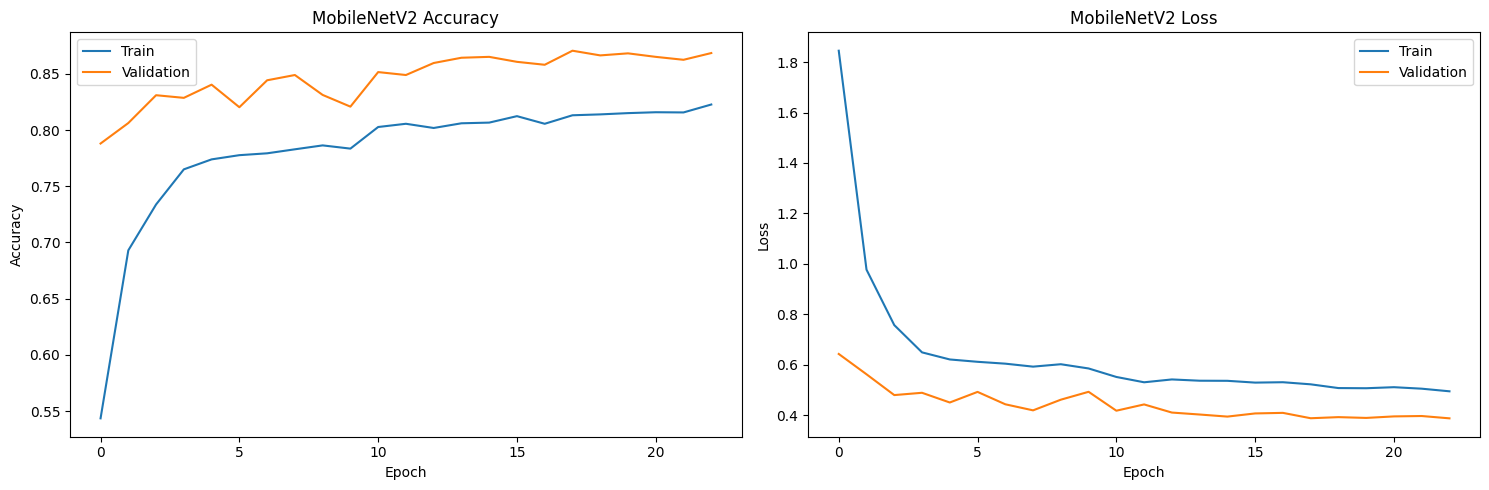

In [ ]:
# === 4. Load MobileNetV2 with proper preprocessing ===
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    alpha=1.0 
)
base_model.trainable = False  # Freeze initially

# === 5. Build Model ===
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x) 
x = Dropout(0.5)(x)
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# === 6. Compile with MobileNet-optimized settings ===
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === 7. Enhanced Callbacks ===
callbacks = [
    EarlyStopping(patience=5, monitor='val_accuracy', restore_best_weights=True),
    ModelCheckpoint('mobilenet_best.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
]

# === 8. Training ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks
)

# === 9. Evaluation ===
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\nTest accuracy: {test_acc:.2%}")

# === 10. Enhanced Visualization ===
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


#### Prediction evaluation
Model Loading: The best model is loaded from the saved file (<best_model>.keras).
- Data Preparation: Test images and labels are extracted from the test dataset for evaluation.
- Predictions: The model predicts class probabilities for the test images, and the predicted labels are determined by selecting the class with the highest probability.
- Metrics Calculation: Key metrics such as accuracy, precision, recall, and F1-score are computed using the true and predicted labels.
- Classification Report: A detailed classification report is generated, showing precision, recall, and F1-score for each class.
- Confusion Matrix: A confusion matrix is plotted using Seaborn to visualize the model's performance across different classes.
- Sample Predictions: Random test samples are displayed with their true labels, predicted labels, and confidence scores to provide a qualitative assessment of the model's predictions.

2025-04-07 14:34:22.463022: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-04-07 14:34:27.274633: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 80ms/step

Classification Report:
              precision    recall  f1-score   support

  brown_rust       0.86      0.80      0.83       486
     healthy       0.83      0.91      0.87       449
      mildew       0.90      0.78      0.84       597
    septoria       0.88      0.91      0.90      1394
 yellow_rust       0.81      0.84      0.83       897

    accuracy                           0.86      3823
   macro avg       0.86      0.85      0.85      3823
weighted avg       0.86      0.86      0.86      3823


Additional Metrics:
Accuracy: 85.95%
Precision: 86.11%
Recall: 85.95%
F1-Score: 85.91%


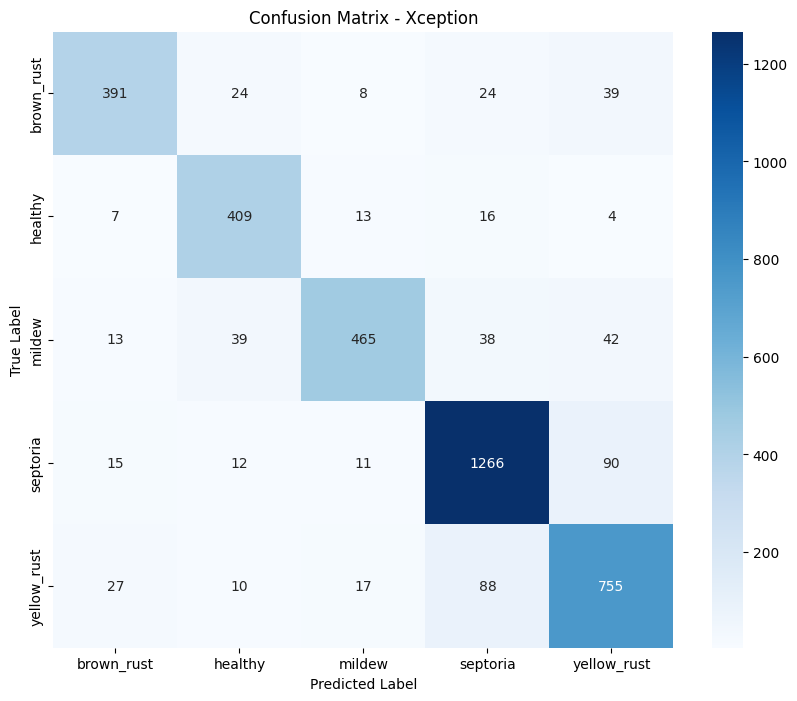

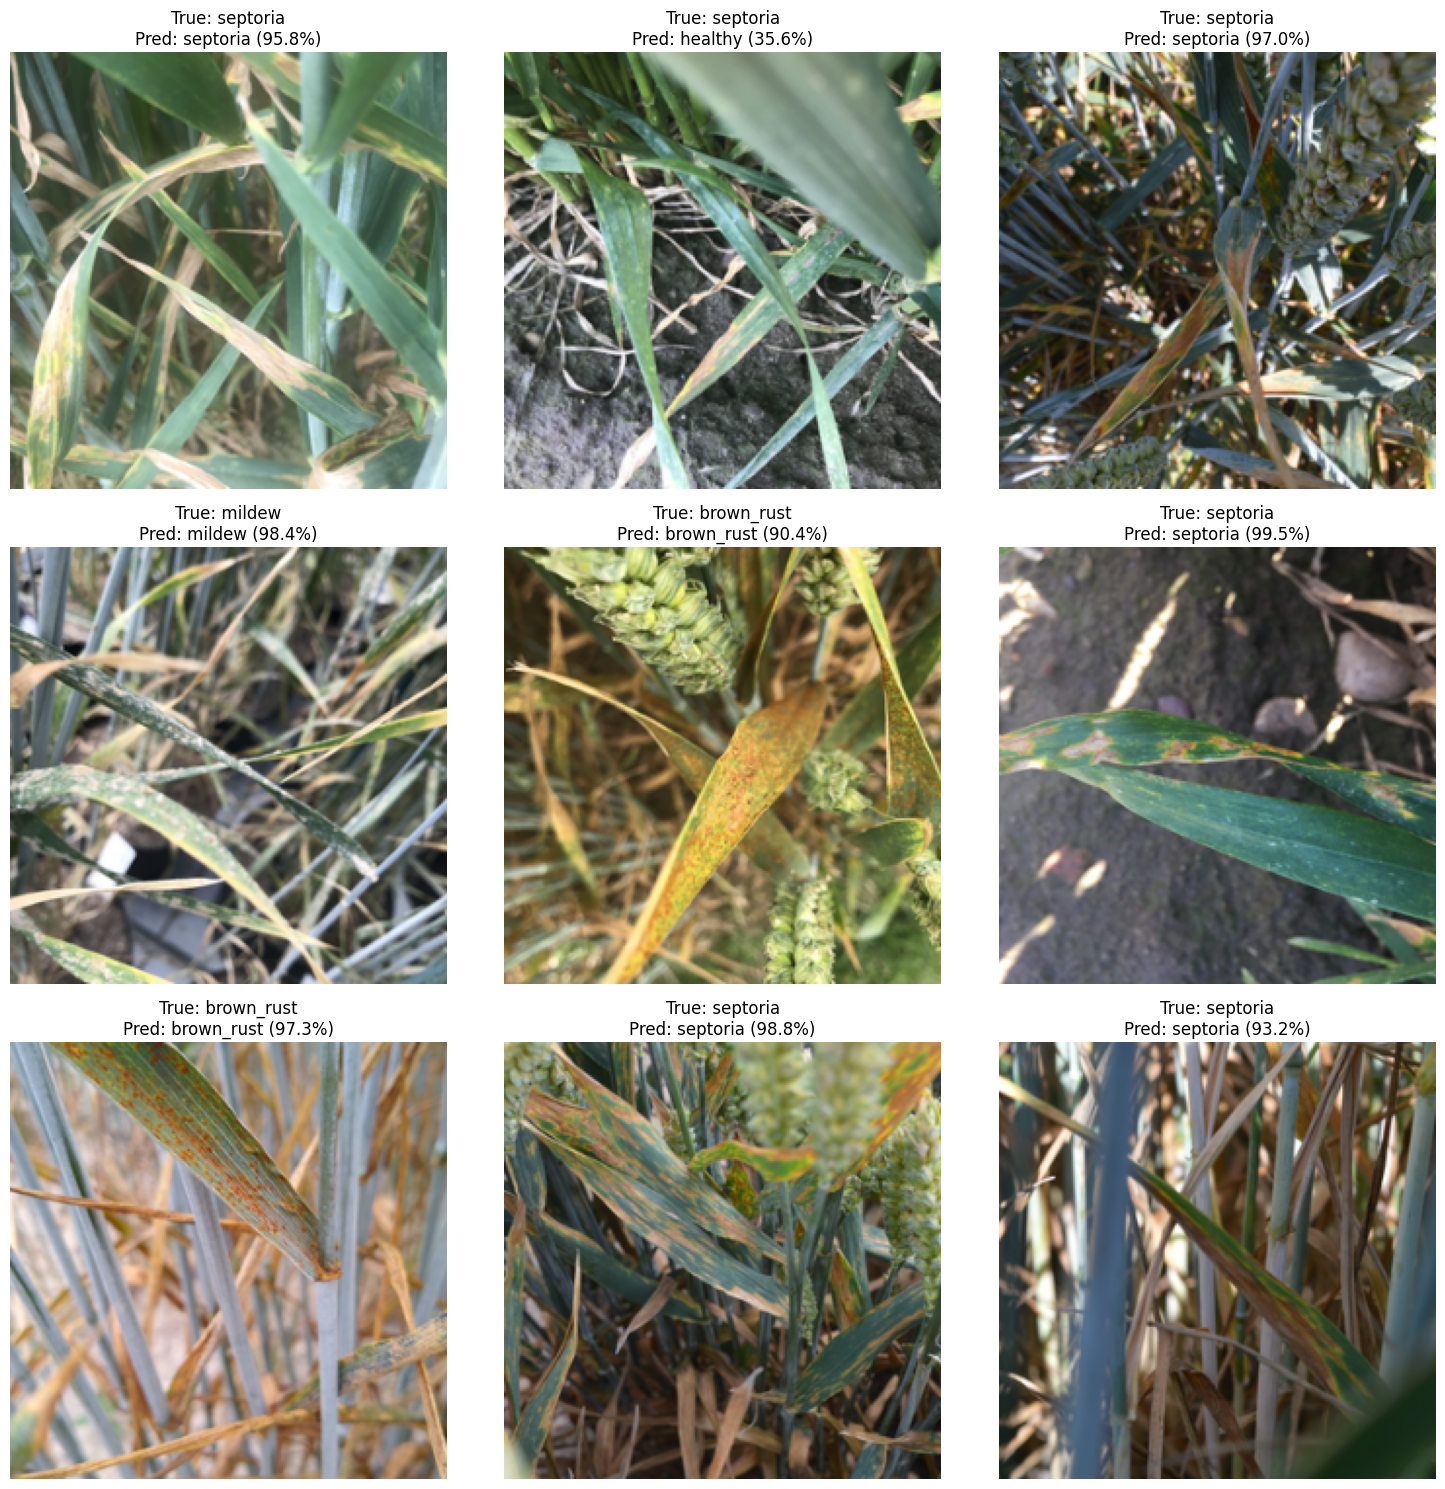

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

model = tf.keras.models.load_model('mobilenet_best.keras')
class_names = train_dataset.class_names

test_images, test_labels = [], []
for img, lbl in test_dataset.unbatch():
    test_images.append(img.numpy())
    test_labels.append(lbl.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

# predictions
predictions = model.predict(test_images, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

# metrics
accuracy = accuracy_score(test_labels, predicted_labels)
precision = precision_score(test_labels, predicted_labels, average='weighted')
recall = recall_score(test_labels, predicted_labels, average='weighted')
f1 = f1_score(test_labels, predicted_labels, average='weighted')

print("\nClassification Report:")
print(classification_report(test_labels, predicted_labels, target_names=class_names))

print("\nAdditional Metrics:")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-Score: {f1:.2%}")

plt.figure(figsize=(10, 8))
cm = confusion_matrix(test_labels, predicted_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Xception')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

plt.figure(figsize=(15, 15))
for i in range(9):  # Show 9 random samples
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(test_images[i].astype('uint8'))  # Assumes RGB images
    true_label = class_names[test_labels[i]]
    pred_label = class_names[predicted_labels[i]]
    confidence = np.max(predictions[i]) * 100
    plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)")
    plt.axis('off')
plt.tight_layout()
plt.show()